In [7]:
from matplotlib import pyplot as plt
from time import time
from scipy.signal import medfilt
import numpy as np
from tqdm.notebook import tqdm

In [3]:
q = 10**9
def fib_tab(n):
    res = [0] * max((n + 1), 2)
    res[0] = 0
    res[1] = 1
    for i in range(2, n + 1):
        res[i] = (res[i - 1] + res[i - 2]) % q
    return res[n]

def fib_tab_exact(n):
    res = [0] * max((n + 1), 2)
    res[0] = 0
    res[1] = 1
    for i in range(2, n + 1):
        res[i] = (res[i - 1] + res[i - 2])
    return res[n]

In [4]:
fib_tab(1000)

849228875

In [5]:
fib_tab_exact(1000)

43466557686937456435688527675040625802564660517371780402481729089536555417949051890403879840079255169295922593080322634775209689623239873322471161642996440906533187938298969649928516003704476137795166849228875

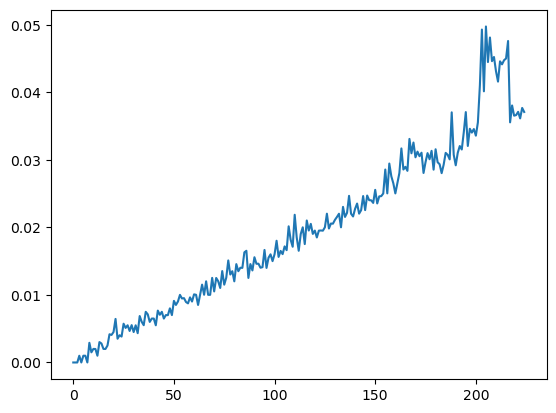

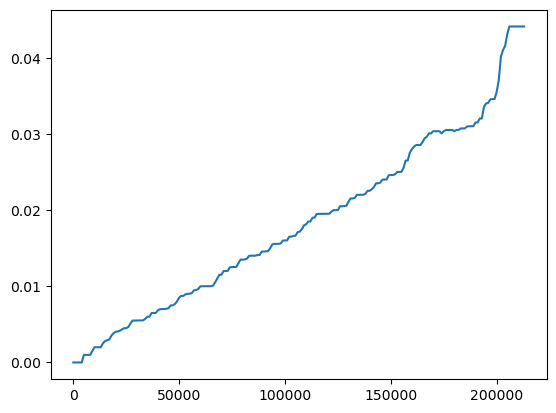

In [19]:
times = []
N_max = 225000
step = 1000

for i in range(1, N_max, step):
    t = time()

    # tabulation:
    x = fib_tab(i)

    times.append(time() - t)
    #print(f'N={i}: {times[-1]:.8f} sec.')

plt.plot(times)
ker = 21
plt.show()
plt.plot(np.arange(1, N_max, step)[:-ker//2], medfilt(times, kernel_size=21)[:-ker//2])
plt.show()

In [24]:
from tqdm.notebook import tqdm

  0%|          | 0/50 [00:00<?, ?it/s]

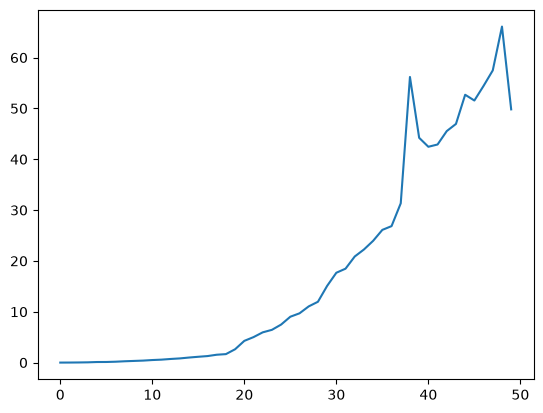

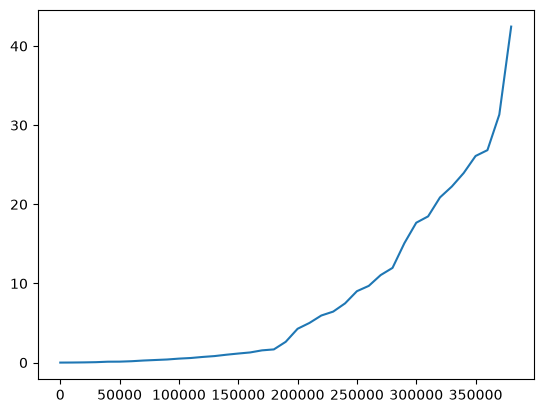

In [8]:
times = []
N_max = 500000
step = 10000

for i in tqdm(range(1, N_max, step)):
    t = time()

    # tabulation:
    x = fib_tab_exact(i)

    times.append(time() - t)
    #print(f'N={i}: {times[-1]:.8f} sec.')

plt.plot(times)
ker = 21
plt.show()
plt.plot(np.arange(1, N_max, step)[:-ker//2], medfilt(times, kernel_size=21)[:-ker//2])
plt.show()

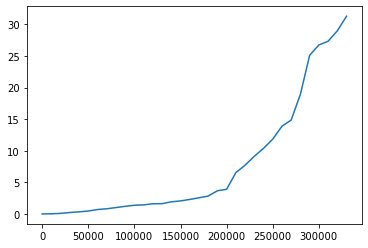

In [31]:
#plt.plot(times)
ker = 21
#plt.show()
plt.plot(np.arange(1, N_max, step)[:len(times)][:-ker//2], medfilt(times, kernel_size=21)[:-ker//2])
plt.show()

In [12]:
for i in [1, 10, 100, 1000, 10000, 100000]:
    print(i, len(str(fib_tab_exact(i))))

1 1
10 2
100 21
1000 209
10000 2090
100000 20899
